# 🫀 CardioAgent-Ops — Module MLOps Audio (Benchmark de 5 algorithmes)

Ce notebook suit les jalons **1 et 2** du PDF :

| Étape | Contenu |
|---|---|
| 0 | Installation + connexion à Google Drive |
| 1 | Inspection de la structure du dataset (`ourdataset`) |
| 2 | Étiquetage (Normal / Pathologique) |
| 3 | Prétraitement : rééchantillonnage **2000 Hz**, filtrage, normalisation, découpage en fenêtres de **5 s** |
| 4 | Extraction des caractéristiques : **MFCC + ZCR** (1D) et **spectrogramme Mel** (2D) |
| 5 | Split Train / Val / Test **par enregistrement** (pas de fuite de données) |
| 6 | Les **5 algorithmes** : Decision Tree, **SVM (RBF)**, CNN custom, ResNet18 (transfer learning), Transformer-CNN |
| 7 | Suivi **MLflow** de chaque run (params, métriques, artefacts) |
| 8 | Choix du meilleur modèle selon le **Recall** de la classe pathologique |
| 9 | Export **ONNX** (`cardio_model.onnx`) + vérification avec ONNX Runtime |

> 💡 **Comment lire ce notebook** : exécute les cellules **dans l'ordre**. Chaque cellule de code est précédée d'une explication.
> Active le GPU : *Exécution → Modifier le type d'exécution → T4 GPU* (utile pour les étapes 6.3 à 6.5, pas obligatoire pour le SVM).

## 0️⃣ Installation et connexion à Google Drive

In [1]:
# Librairies non installées par défaut sur Colab
!pip install -q mlflow onnx onnxruntime skl2onnx

# Connexion à Google Drive (une fenêtre te demandera d'autoriser l'accès)
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### ⚙️ Configuration (seule cellule à modifier si besoin)
- `DATA_DIR` : dossier du dataset dans ton Drive (`ourdataset`).
- `OUTPUT_DIR` : où seront sauvegardés `cardio_model.onnx`, les features et la base MLflow.
- Paramètres du signal imposés par le PDF : **2000 Hz**, fenêtre de **5 s**.

In [ ]:
import os, json, warnings, random
import numpy as np
warnings.filterwarnings("ignore")

# ======== À ADAPTER SI BESOIN ========
DATA_DIR   = "DATA_DIR"          # dossier du dataset
OUTPUT_DIR = "OUTPUT_DIR"  # sorties (onnx, mlflow...)
LABEL_CSV  = None   # ex: "/content/drive/MyDrive/ourdataset/labels.csv" (colonnes: filename,label) sinon None
# =====================================

SR = 2000                 # fréquence d'échantillonnage cible (PDF : 2000 Hz)
DURATION = 5              # durée d'une fenêtre en secondes (PDF : 2 s ou 5 s)
N_SAMPLES = SR * DURATION # 10 000 échantillons par fenêtre
MAX_SEG_PER_FILE = 6      # on limite le nb de fenêtres par fichier (évite qu'un long enregistrement domine)
N_MFCC, N_MELS, N_FFT, HOP = 13, 40, 256, 64
SEED = 42

os.makedirs(OUTPUT_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
print("Dataset existe :", os.path.exists(DATA_DIR))

Dataset existe : True


## 1️⃣ Inspection de la structure du dataset
Avant tout traitement, on regarde **ce qu'il y a dans le dossier** : sous-dossiers, extensions de fichiers, nombre de `.wav`, présence de fichiers CSV de labels.
C'est indispensable car PASCAL et PhysioNet n'ont pas la même organisation :
- **PASCAL** : le label est dans le *nom du fichier / dossier* (`normal__...`, `murmur__...`, `extrastole__...`, `artifact__...`).
- **PhysioNet 2016** : le label est dans un fichier `REFERENCE.csv` par dossier (`-1` = normal, `1` = anormal).

In [3]:
from collections import Counter

ext_counter = Counter()
folders = Counter()
for root, dirs, files in os.walk(DATA_DIR):
    for f in files:
        ext_counter[os.path.splitext(f)[1].lower()] += 1
        if f.lower().endswith(".wav"):
            folders[os.path.relpath(root, DATA_DIR)] += 1

print("Extensions trouvées :", dict(ext_counter))
print("\nNombre de .wav par sous-dossier :")
for k, v in sorted(folders.items()):
    print(f"  {k or '.':60s} {v}")

print("\nExemples de fichiers :")
shown = 0
for root, dirs, files in os.walk(DATA_DIR):
    for f in files[:3]:
        print("  ", os.path.relpath(os.path.join(root, f), DATA_DIR))
    shown += 1
    if shown > 8: break

Extensions trouvées : {'.wav': 3355}

Nombre de .wav par sous-dossier :
  train/abnormal                                               858
  train/normal                                                 2497

Exemples de fichiers :
   train/abnormal/a0014.wav
   train/abnormal/a0022.wav
   train/abnormal/a0013.wav
   train/normal/e01329.wav
   train/normal/e01407.wav
   train/normal/e01435.wav


## 2️⃣ Étiquetage : Normal (0) vs Pathologique (1)
On crée une liste `records = [(chemin, label)]`. Règles (dans cet ordre) :
1. Si un `REFERENCE.csv` existe (PhysioNet) → `1` = pathologique, `-1` = normal.
2. Sinon, si `LABEL_CSV` est fourni → on l'utilise.
3. Sinon on lit le **nom du dossier / fichier** : `murmur`, `extrasystole/extrastole`, `abnormal` → **1** ; `normal` → **0**.
4. Les enregistrements `artifact` (bruit, pas un cœur) et les fichiers sans label sont **ignorés**.

⚠️ **Regarde bien le résumé affiché** : si le nombre de fichiers ignorés est énorme, il faut adapter les mots-clés ci-dessous à *ton* dataset.

In [4]:
import pandas as pd

PATHO_KEYS    = ["murmur", "extrasystole", "extrastole", "abnormal", "pathologic", "patholog", "anormal", "disease"]
NORMAL_KEYS   = ["normal", "healthy", "sain"]
ARTIFACT_KEYS = ["artifact", "artefact", "noise"]

# 1) Lecture des REFERENCE.csv (PhysioNet) : nom_fichier -> label
ref_map = {}
for root, dirs, files in os.walk(DATA_DIR):
    for f in files:
        if f.upper() == "REFERENCE.CSV":
            df = pd.read_csv(os.path.join(root, f), header=None, names=["name", "label"])
            for n, l in zip(df["name"], df["label"]):
                ref_map[(root, str(n))] = 1 if int(l) == 1 else 0

# 2) CSV de labels optionnel
csv_map = {}
if LABEL_CSV:
    d = pd.read_csv(LABEL_CSV)
    csv_map = {os.path.splitext(str(a))[0]: int(b) for a, b in zip(d.iloc[:, 0], d.iloc[:, 1])}

def infer_label(root, fname):
    stem = os.path.splitext(fname)[0]
    if (root, stem) in ref_map:  return ref_map[(root, stem)]
    if stem in csv_map:          return csv_map[stem]
    text = (os.path.relpath(root, DATA_DIR) + "/" + fname).lower()
    if any(k in text for k in ARTIFACT_KEYS): return "artifact"
    if any(k in text for k in PATHO_KEYS):    return 1      # on teste "patho" AVANT "normal" car "abnormal" contient "normal"
    if any(k in text for k in NORMAL_KEYS):   return 0
    return None

records, skipped = [], Counter()
for root, dirs, files in os.walk(DATA_DIR):
    for f in files:
        if f.lower().endswith(".wav"):
            lab = infer_label(root, f)
            if lab in (0, 1):
                records.append((os.path.join(root, f), lab))
            else:
                skipped[str(lab)] += 1

df_rec = pd.DataFrame(records, columns=["path", "label"])
print("Fichiers retenus :", len(df_rec))
print(df_rec["label"].value_counts().rename({0: "Normal (0)", 1: "Pathologique (1)"}))
print("Ignorés (artifact / sans label) :", dict(skipped))
assert len(df_rec) > 0, "Aucun fichier étiqueté ! Adapte PATHO_KEYS/NORMAL_KEYS ou fournis LABEL_CSV."

Fichiers retenus : 3355
label
Normal (0)          2497
Pathologique (1)     858
Name: count, dtype: int64
Ignorés (artifact / sans label) : {}


## 3️⃣ Prétraitement du signal
Pour chaque `.wav` :
1. **Rééchantillonnage à 2000 Hz** (`librosa.load(sr=2000)`) → tous les fichiers ont la même fréquence.
2. **Filtre passe-bande 25–400 Hz** : l'essentiel des bruits cardiaques (B1, B2, souffles) est dans cette bande ; on enlève le bruit grave (respiration, mouvement) et aigu.
3. **Normalisation d'amplitude** (division par le max absolu) → l'intensité du micro n'influence plus le modèle.
4. **Découpage en fenêtres de 5 s** (10 000 échantillons). Les fichiers plus courts sont complétés (padding).

In [5]:
import librosa
from scipy.signal import butter, filtfilt

def bandpass(y, low=25, high=400, fs=SR, order=3):
    nyq = fs / 2
    b, a = butter(order, [low / nyq, min(high, nyq * 0.99) / nyq], btype="band")
    return filtfilt(b, a, y)

def preprocess_file(path):
    # Charge, rééchantillonne, filtre, normalise, puis découpe en fenêtres de N_SAMPLES.
    y, _ = librosa.load(path, sr=SR, mono=True)
    if len(y) < SR:                       # fichier quasi vide -> on le saute
        return []
    y = y - np.mean(y)                    # enlève la composante continue
    y = bandpass(y)
    y = y / (np.max(np.abs(y)) + 1e-8)    # normalisation amplitude [-1, 1]
    segs = []
    for start in range(0, len(y), N_SAMPLES):
        seg = y[start:start + N_SAMPLES]
        if len(seg) < N_SAMPLES * 0.5:    # morceau final trop court -> ignoré
            continue
        if len(seg) < N_SAMPLES:          # padding avec des zéros
            seg = np.pad(seg, (0, N_SAMPLES - len(seg)))
        segs.append(seg.astype(np.float32))
    if len(segs) > MAX_SEG_PER_FILE:      # on garde des fenêtres réparties sur tout le fichier
        idx = np.linspace(0, len(segs) - 1, MAX_SEG_PER_FILE).astype(int)
        segs = [segs[i] for i in idx]
    return segs

# Test rapide sur un fichier
test_segs = preprocess_file(df_rec.path.iloc[0])
print("Nombre de fenêtres :", len(test_segs), "| forme d'une fenêtre :", test_segs[0].shape)

Nombre de fenêtres : 6 | forme d'une fenêtre : (10000,)


## 4️⃣ Extraction des caractéristiques (MFCC, ZCR, Spectrogramme Mel)

**Spectrogramme Mel** (image 2D : fréquence × temps) → pour les modèles CNN / ResNet / Transformer.
On applique la STFT puis des filtres « Mel » (échelle proche de l'oreille humaine) et on passe en dB (log).

**MFCC** (*Mel-Frequency Cepstral Coefficients*) : compression du spectrogramme Mel en 13 coefficients par instant (via DCT). Ils résument la « forme » du spectre.
Pour les modèles classiques (Decision Tree, SVM) qui attendent un **vecteur 1D**, on résume chaque coefficient dans le temps par sa **moyenne** et son **écart-type** (+ les deltas = variation dans le temps).

**ZCR** (*Zero Crossing Rate*) : fréquence de passage par zéro du signal (mesure de « bruit »/souffle).

Vecteur 1D final : MFCC(mean,std)=26 + Δ-MFCC(mean,std)=26 + ZCR(2) + RMS(2) = **56 features**.

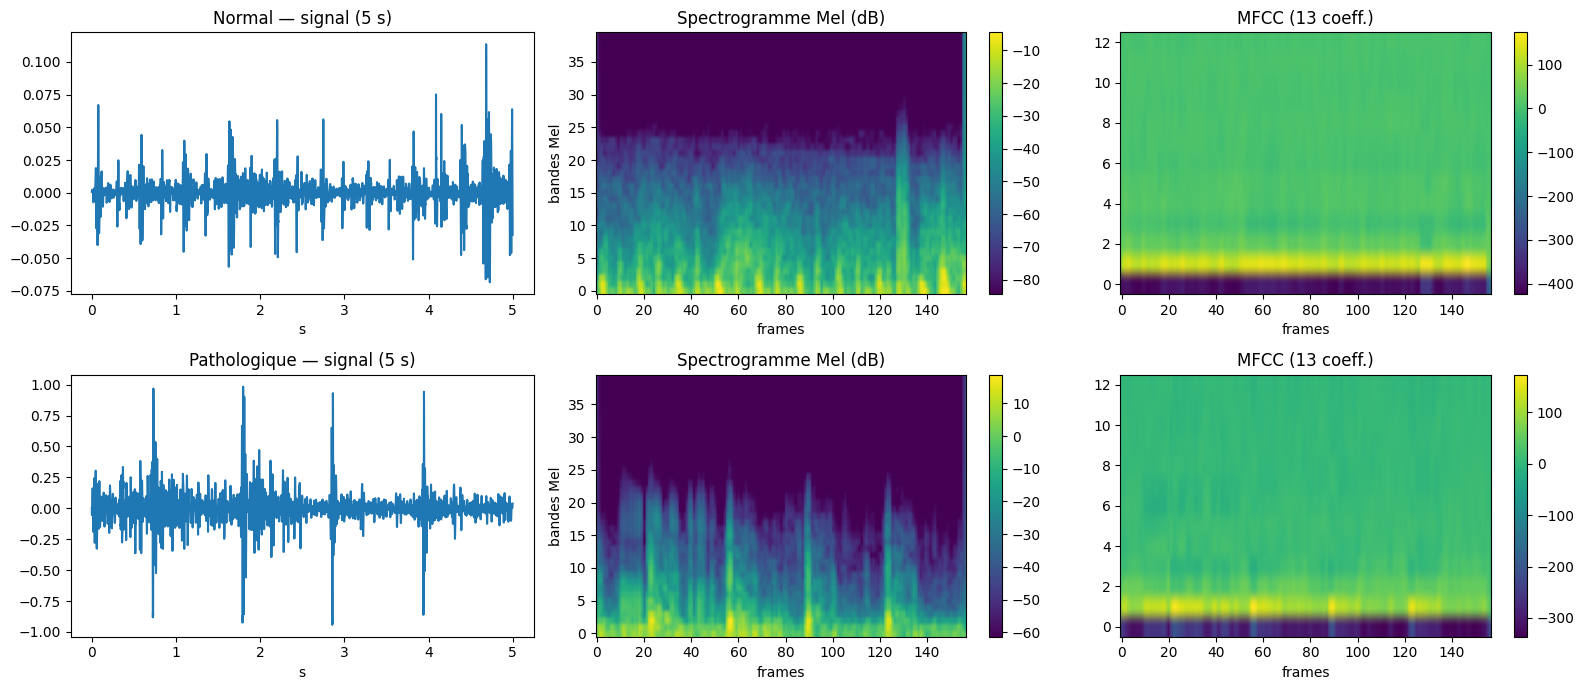

In [6]:
def mel_spectrogram_db(seg):
    S = librosa.feature.melspectrogram(y=seg, sr=SR, n_fft=N_FFT, hop_length=HOP,
                                       n_mels=N_MELS, fmin=20, fmax=900)
    return librosa.power_to_db(S, ref=1.0, top_db=80).astype(np.float32)   # (40, ~157)

def feature_vector(seg, S_db):
    mfcc  = librosa.feature.mfcc(S=S_db, n_mfcc=N_MFCC)                    # (13, T)
    delta = librosa.feature.delta(mfcc)
    zcr   = librosa.feature.zero_crossing_rate(seg, frame_length=N_FFT, hop_length=HOP)
    rms   = librosa.feature.rms(y=seg, frame_length=N_FFT, hop_length=HOP)
    return np.concatenate([mfcc.mean(1), mfcc.std(1), delta.mean(1), delta.std(1),
                           [zcr.mean(), zcr.std(), rms.mean(), rms.std()]]).astype(np.float32)

# ---- Visualisation sur un exemple normal et un exemple pathologique ----
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for r, lab in enumerate([0, 1]):
    p = df_rec[df_rec.label == lab].path.iloc[0]
    seg = preprocess_file(p)[0]
    S = mel_spectrogram_db(seg)
    mfcc = librosa.feature.mfcc(S=S, n_mfcc=N_MFCC)
    name = "Normal" if lab == 0 else "Pathologique"
    axes[r, 0].plot(np.arange(len(seg)) / SR, seg); axes[r, 0].set_title(f"{name} — signal (5 s)"); axes[r, 0].set_xlabel("s")
    im = axes[r, 1].imshow(S, aspect="auto", origin="lower"); axes[r, 1].set_title("Spectrogramme Mel (dB)")
    axes[r, 1].set_xlabel("frames"); axes[r, 1].set_ylabel("bandes Mel"); plt.colorbar(im, ax=axes[r, 1])
    im = axes[r, 2].imshow(mfcc, aspect="auto", origin="lower"); axes[r, 2].set_title("MFCC (13 coeff.)")
    axes[r, 2].set_xlabel("frames"); plt.colorbar(im, ax=axes[r, 2])
plt.tight_layout(); plt.show()

## 5️⃣ Split Train / Validation / Test — **par enregistrement**
⚠️ Point méthodologique important : un même fichier donne plusieurs fenêtres de 5 s. Si on mélangeait les fenêtres au hasard, des fenêtres du **même patient** seraient dans le train *et* le test → le modèle « triche » (**data leakage**).
On sépare donc d'abord les **fichiers** (70 % train / 15 % val / 15 % test, stratifié), puis on extrait les fenêtres de chaque groupe.
- **Train** : apprendre. **Validation** : régler les hyperparamètres / arrêter l'entraînement. **Test** : note finale, jamais utilisée pour apprendre.

In [7]:
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

df_tr, df_tmp = train_test_split(df_rec, test_size=0.30, stratify=df_rec.label, random_state=SEED)
df_va, df_te  = train_test_split(df_tmp, test_size=0.50, stratify=df_tmp.label, random_state=SEED)
print("Fichiers  train/val/test :", len(df_tr), len(df_va), len(df_te))

CACHE = os.path.join(OUTPUT_DIR, "features_cache.npz")

def build(df_part, desc):
    X1d, X2d, y, groups = [], [], [], []
    for gid, (p, lab) in enumerate(tqdm(zip(df_part.path, df_part.label), total=len(df_part), desc=desc)):
        try:
            for seg in preprocess_file(p):
                S = mel_spectrogram_db(seg)
                X1d.append(feature_vector(seg, S)); X2d.append(S); y.append(lab); groups.append(p)
        except Exception as e:
            print("Erreur sur", p, e)
    return np.array(X1d), np.array(X2d), np.array(y), np.array(groups)

if os.path.exists(CACHE):
    print("Chargement depuis le cache (déjà calculé) …")
    z = np.load(CACHE, allow_pickle=True)
    X1_tr, X2_tr, y_tr, g_tr = z["X1_tr"], z["X2_tr"], z["y_tr"], z["g_tr"]
    X1_va, X2_va, y_va, g_va = z["X1_va"], z["X2_va"], z["y_va"], z["g_va"]
    X1_te, X2_te, y_te, g_te = z["X1_te"], z["X2_te"], z["y_te"], z["g_te"]
else:
    X1_tr, X2_tr, y_tr, g_tr = build(df_tr, "train")
    X1_va, X2_va, y_va, g_va = build(df_va, "val")
    X1_te, X2_te, y_te, g_te = build(df_te, "test")
    np.savez_compressed(CACHE, X1_tr=X1_tr, X2_tr=X2_tr, y_tr=y_tr, g_tr=g_tr,
                        X1_va=X1_va, X2_va=X2_va, y_va=y_va, g_va=g_va,
                        X1_te=X1_te, X2_te=X2_te, y_te=y_te, g_te=g_te)

print("\nVecteurs 1D :", X1_tr.shape, X1_va.shape, X1_te.shape)
print("Spectrogrammes 2D :", X2_tr.shape, X2_va.shape, X2_te.shape)
for n, y in [("train", y_tr), ("val", y_va), ("test", y_te)]:
    print(f"{n:5s} fenêtres : normal={np.sum(y==0)}  pathologique={np.sum(y==1)}  ({np.mean(y==1)*100:.1f}% patho)")

Fichiers  train/val/test : 2348 503 504


train:   0%|          | 0/2348 [00:00<?, ?it/s]

val:   0%|          | 0/503 [00:00<?, ?it/s]

test:   0%|          | 0/504 [00:00<?, ?it/s]


Vecteurs 1D : (8745, 56) (1869, 56) (1867, 56)
Spectrogrammes 2D : (8745, 40, 157) (1869, 40, 157) (1867, 40, 157)
train fenêtres : normal=6489  pathologique=2256  (25.8% patho)
val   fenêtres : normal=1362  pathologique=507  (27.1% patho)
test  fenêtres : normal=1343  pathologique=524  (28.1% patho)


### Déséquilibre de classes
Si une classe est beaucoup plus rare, un modèle peut avoir 90 % d'accuracy en prédisant toujours « normal » — mais **rater tous les malades**.
Nous traitons ça avec des **poids de classes** (`class_weight='balanced'` pour sklearn, `CrossEntropyLoss(weight=…)` pour PyTorch) : une erreur sur la classe rare coûte plus cher.

## 6️⃣ Métriques et suivi MLflow
**Métrique clé du projet : le Recall (rappel) sur la classe pathologique** = parmi tous les vrais malades, combien en détecte-t-on ?
`Recall = TP / (TP + FN)` → en médecine, un **faux négatif** (malade déclaré sain) est le pire des cas.

Mais un modèle qui prédit « pathologique » pour tout le monde aurait Recall = 1. On suit donc aussi la **spécificité** (bien reconnaître les sains), la précision, le F1 et l'AUC.

**MLflow** : à chaque entraînement on enregistre un *run* avec ses paramètres, ses métriques, la matrice de confusion et le modèle.

In [8]:
import mlflow, joblib, time
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

# Base MLflow locale (SQLite) ; copiée dans Drive à la fin pour ne rien perdre
TRACKING_DB = "sqlite:////content/mlflow.db"
mlflow.set_tracking_uri(TRACKING_DB)
EXP_NAME = "CardioAgent-Ops_Audio_Benchmark"
if mlflow.get_experiment_by_name(EXP_NAME) is None:
    mlflow.create_experiment(EXP_NAME, artifact_location="/content/mlartifacts")
mlflow.set_experiment(EXP_NAME)

def compute_metrics(y_true, y_pred, y_proba):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "accuracy":    accuracy_score(y_true, y_pred),
        "recall_patho": recall_score(y_true, y_pred, pos_label=1, zero_division=0),   # ⭐ métrique principale
        "specificity": tn / (tn + fp + 1e-9),
        "precision":   precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "f1":          f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "auc":         roc_auc_score(y_true, y_proba) if len(np.unique(y_true)) > 1 else float("nan"),
    }

RESULTS = {}   # nom -> dict (métriques test, objet modèle, type...)

def log_to_mlflow(name, params, m_val, m_test, y_te, pred_te, extra_artifacts=(), history=None):
    with mlflow.start_run(run_name=name):
        mlflow.log_params(params)
        mlflow.log_metrics({f"val_{k}": v for k, v in m_val.items()})
        mlflow.log_metrics({f"test_{k}": v for k, v in m_test.items()})
        if history:                                   # courbes de perte epoch par epoch
            for ep, (tl, vl) in enumerate(zip(history["train_loss"], history["val_loss"])):
                mlflow.log_metric("train_loss", tl, step=ep); mlflow.log_metric("val_loss", vl, step=ep)
        fig, ax = plt.subplots(figsize=(4, 4))
        ConfusionMatrixDisplay(confusion_matrix(y_te, pred_te), display_labels=["Normal", "Patho"]).plot(ax=ax, colorbar=False)
        ax.set_title(f"{name} — Test"); mlflow.log_figure(fig, "confusion_matrix_test.png"); plt.show()
        for p in extra_artifacts: mlflow.log_artifact(p)
        print(f"✅ [{name}] TEST → recall_patho={m_test['recall_patho']:.3f} | spécificité={m_test['specificity']:.3f} | "
              f"F1={m_test['f1']:.3f} | AUC={m_test['auc']:.3f}")

2026/11/11 22:33:51 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/11 22:33:51 INFO mlflow.store.db.utils: Updating database tables


## 6.1 — Algorithme 1 : Decision Tree (Arbre de décision) sur MFCC 1D
Un arbre pose une suite de questions « si MFCC_3 < 0.7 alors … » jusqu'à une décision.
- ✅ Facile à interpréter, rapide.
- ❌ Tend à **sur-apprendre** (surtout si profond) → on limite `max_depth` et `min_samples_leaf` via une recherche (GridSearch).
La validation croisée utilise `GroupKFold` (groupes = fichier) pour éviter la fuite de données.

Meilleurs hyperparamètres : {'clf__max_depth': 3, 'clf__min_samples_leaf': 5}


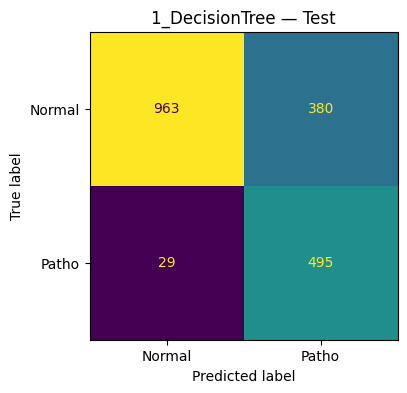

✅ [1_DecisionTree] TEST → recall_patho=0.945 | spécificité=0.717 | F1=0.708 | AUC=0.875


In [9]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, GroupKFold

t0 = time.time()
pipe_dt = Pipeline([("scaler", StandardScaler()),
                    ("clf", DecisionTreeClassifier(class_weight="balanced", random_state=SEED))])
grid_dt = {"clf__max_depth": [3, 5, 8, 12], "clf__min_samples_leaf": [5, 20, 50]}
gs_dt = GridSearchCV(pipe_dt, grid_dt, scoring="recall", cv=GroupKFold(n_splits=3), n_jobs=-1)
gs_dt.fit(X1_tr, y_tr, groups=g_tr)
best_dt = gs_dt.best_estimator_
print("Meilleurs hyperparamètres :", gs_dt.best_params_)

def eval_sklearn(model, X, y):
    return compute_metrics(y, model.predict(X), model.predict_proba(X)[:, 1])

m_val, m_test = eval_sklearn(best_dt, X1_va, y_va), eval_sklearn(best_dt, X1_te, y_te)
joblib.dump(best_dt, "/content/decision_tree.joblib")
log_to_mlflow("1_DecisionTree", {**gs_dt.best_params_, "features": "MFCC+ZCR 1D (56)", "train_time_s": round(time.time()-t0, 1)},
              m_val, m_test, y_te, best_dt.predict(X1_te), ["/content/decision_tree.joblib"])
RESULTS["DecisionTree"] = dict(kind="sklearn", model=best_dt, val=m_val, test=m_test, n_features=X1_tr.shape[1])

## 6.2 — Algorithme 2 : **SVM (Support Vector Machine) noyau RBF** ⭐

> Cette section est **détaillée exprès** : le professeur veut voir le SVM. Lis les commentaires, ils expliquent chaque ligne.

### 🧠 L'idée en une phrase
Le SVM cherche la **frontière (hyperplan) qui sépare les deux classes avec la plus grande marge possible**. Les points les plus proches de cette frontière, qui la « soutiennent », s'appellent les **vecteurs de support** (*support vectors*). Seuls eux comptent ; les autres points n'influencent pas la frontière.

### 📐 Maths minimales
Pour un point `x`, la décision est `f(x) = Σ αᵢ · yᵢ · K(xᵢ, x) + b` (somme sur les vecteurs de support).
Si `f(x) > 0` → pathologique, sinon → normal.

### 🪄 Le « kernel trick » (noyau RBF)
Si les classes ne sont pas séparables par une droite, on les projette (implicitement) dans un espace de dimension supérieure où elles le deviennent.
Le noyau **RBF** (*Radial Basis Function*) mesure la **similarité** entre 2 points :  `K(x, x') = exp(−γ · ‖x − x'‖²)`
→ proche = similarité ≈ 1 ; loin = ≈ 0.

### 🎛️ Les 2 hyperparamètres à comprendre
| Param | Rôle | Trop petit | Trop grand |
|---|---|---|---|
| **C** | Pénalité des erreurs (compromis marge large ↔ peu d'erreurs) | marge large, tolère les erreurs → *sous-apprentissage* | veut zéro erreur sur le train → *sur-apprentissage* |
| **γ (gamma)** | « Rayon d'influence » d'un point | frontière très lisse (presque linéaire) → *sous-apprentissage* | chaque point crée son îlot → *sur-apprentissage* |

### ⚠️ Pourquoi `StandardScaler` est OBLIGATOIRE pour un SVM
Le SVM utilise des **distances**. Si une feature va de 0 à 1000 et une autre de 0 à 0.01, la première écrase la seconde. On standardise (moyenne 0, écart-type 1) → toutes les features ont le même poids.
Et `class_weight='balanced'` donne plus de poids à la classe rare.

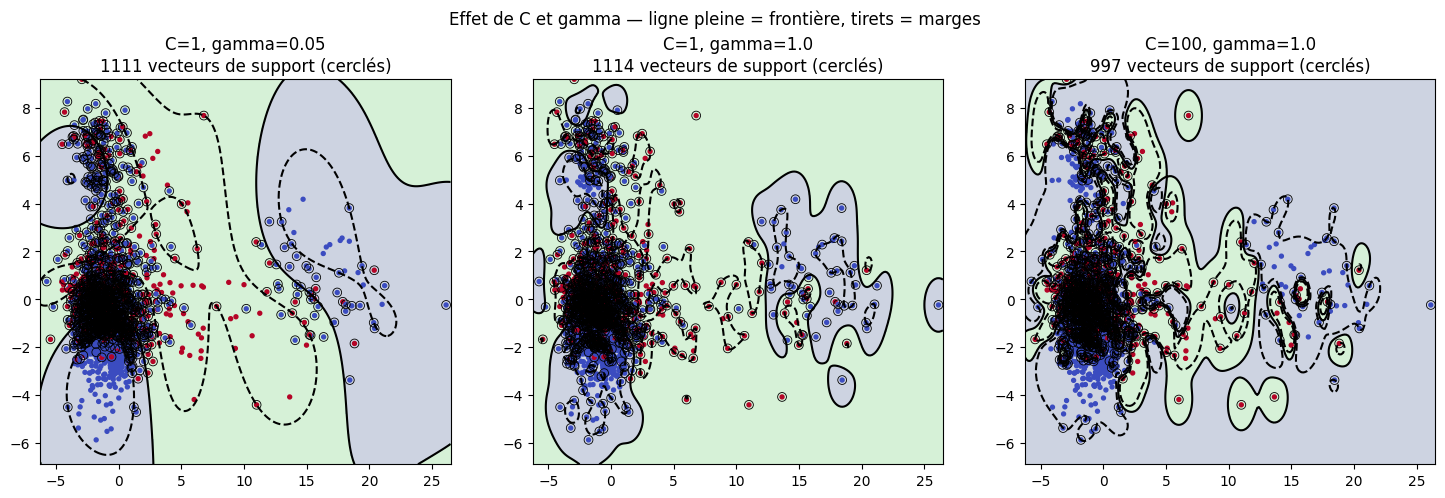

In [10]:
from sklearn.svm import SVC
from sklearn.decomposition import PCA

# ---------- (A) Intuition visuelle : SVM RBF en 2D ----------
# On réduit les 56 features à 2 composantes (PCA) JUSTE pour dessiner la frontière de décision.
# (Le vrai modèle plus bas utilise bien les 56 features.)
sc_demo = StandardScaler().fit(X1_tr)
pca = PCA(n_components=2, random_state=SEED).fit(sc_demo.transform(X1_tr))
Z_tr = pca.transform(sc_demo.transform(X1_tr))
idx = np.random.RandomState(SEED).choice(len(Z_tr), size=min(1500, len(Z_tr)), replace=False)  # sous-échantillon pour la vitesse

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (C_, gam) in zip(axes, [(1, 0.05), (1, 1.0), (100, 1.0)]):
    demo = SVC(kernel="rbf", C=C_, gamma=gam, class_weight="balanced").fit(Z_tr[idx], y_tr[idx])
    xx, yy = np.meshgrid(np.linspace(Z_tr[:, 0].min(), Z_tr[:, 0].max(), 250),
                         np.linspace(Z_tr[:, 1].min(), Z_tr[:, 1].max(), 250))
    zz = demo.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz > 0, alpha=0.25)                      # zone prédite pathologique / normale
    ax.contour(xx, yy, zz, levels=[-1, 0, 1], linestyles=["--", "-", "--"], colors="k")  # frontière (0) et marges (±1)
    ax.scatter(Z_tr[idx, 0], Z_tr[idx, 1], c=y_tr[idx], s=8, cmap="coolwarm")
    ax.scatter(demo.support_vectors_[:, 0], demo.support_vectors_[:, 1], s=40, facecolors="none", edgecolors="k", linewidths=0.6)
    ax.set_title(f"C={C_}, gamma={gam}\n{len(demo.support_vectors_)} vecteurs de support (cerclés)")
plt.suptitle("Effet de C et gamma — ligne pleine = frontière, tirets = marges", y=1.02); plt.show()

In [11]:
# ---------- (B) Sous-apprentissage vs sur-apprentissage : balayage de gamma ----------
# On garde C=1 et on fait varier gamma. On compare le recall sur TRAIN et sur VALIDATION.
# Si train >> val  => sur-apprentissage (le modèle a « appris par cœur »).
rows = []
sc = StandardScaler().fit(X1_tr)
Xs_tr, Xs_va = sc.transform(X1_tr), sc.transform(X1_va)
for gam in [1e-4, 1e-3, 1e-2, 1e-1, 1.0]:
    m = SVC(kernel="rbf", C=1, gamma=gam, class_weight="balanced").fit(Xs_tr, y_tr)
    rows.append(dict(gamma=gam,
                     recall_train=recall_score(y_tr, m.predict(Xs_tr)),
                     recall_val=recall_score(y_va, m.predict(Xs_va)),
                     nb_support_vectors=int(m.n_support_.sum())))
print(pd.DataFrame(rows).to_string(index=False))

 gamma  recall_train  recall_val  nb_support_vectors
0.0001      0.866578    0.834320                6144
0.0010      0.900709    0.865878                4450
0.0100      0.965426    0.891519                3340
0.1000      1.000000    0.627219                5689
1.0000      1.000000    0.000000                8743


Fitting 3 folds for each of 12 candidates, totalling 36 fits
Meilleurs hyperparamètres SVM : {'clf__C': 0.5, 'clf__gamma': 'scale'}
Nombre de vecteurs de support : 3543 sur 8745 échantillons d'entraînement


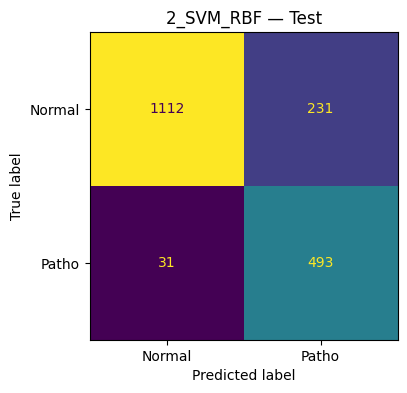

✅ [2_SVM_RBF] TEST → recall_patho=0.941 | spécificité=0.828 | F1=0.790 | AUC=0.948


In [12]:
# ---------- (C) Entraînement du vrai SVM + recherche des meilleurs C et gamma ----------
t0 = time.time()

pipe_svm = Pipeline([
    ("scaler", StandardScaler()),                     # 1) mise à l'échelle (obligatoire pour le SVM)
    ("clf", SVC(kernel="rbf",                         # 2) noyau RBF (gaussien)
                class_weight="balanced",              #    compense le déséquilibre normal/patho
                probability=True,                     #    permet d'obtenir des probabilités (utile pour l'AUC et l'ONNX)
                random_state=SEED)),
])

# Grille : C (pénalité des erreurs) x gamma (rayon d'influence)
grid_svm = {"clf__C": [0.5, 1, 10, 100],
            "clf__gamma": ["scale", 0.001, 0.01]}      # 'scale' = 1 / (nb_features * variance)

# GridSearch = on teste toutes les combinaisons avec validation croisée (3 plis).
# scoring='recall' : on optimise directement le rappel de la classe pathologique (consigne du PDF).
# GroupKFold : toutes les fenêtres d'un même fichier restent dans le même pli (pas de fuite).
gs_svm = GridSearchCV(pipe_svm, grid_svm, scoring="recall", cv=GroupKFold(n_splits=3), n_jobs=-1, verbose=1)
gs_svm.fit(X1_tr, y_tr, groups=g_tr)
best_svm = gs_svm.best_estimator_
print("Meilleurs hyperparamètres SVM :", gs_svm.best_params_)
print("Nombre de vecteurs de support :", int(best_svm.named_steps["clf"].n_support_.sum()),
      "sur", len(X1_tr), "échantillons d'entraînement")

m_val, m_test = eval_sklearn(best_svm, X1_va, y_va), eval_sklearn(best_svm, X1_te, y_te)
joblib.dump(best_svm, "/content/svm_rbf.joblib")
log_to_mlflow("2_SVM_RBF",
              {**gs_svm.best_params_, "kernel": "rbf", "class_weight": "balanced",
               "n_support_vectors": int(best_svm.named_steps["clf"].n_support_.sum()),
               "features": "MFCC+ZCR 1D (56)", "train_time_s": round(time.time()-t0, 1)},
              m_val, m_test, y_te, best_svm.predict(X1_te), ["/content/svm_rbf.joblib"])
RESULTS["SVM_RBF"] = dict(kind="sklearn", model=best_svm, val=m_val, test=m_test, n_features=X1_tr.shape[1])

### 🗣️ Ce que tu peux dire au professeur sur le SVM
1. *« Le SVM cherche l'hyperplan à marge maximale ; seuls les vecteurs de support définissent la frontière. »*
2. *« Les données MFCC ne sont pas linéairement séparables, j'utilise donc le noyau RBF (kernel trick) qui calcule une similarité exp(−γ‖x−x'‖²). »*
3. *« J'ai standardisé les features (indispensable car le SVM repose sur des distances) et utilisé `class_weight='balanced'` pour le déséquilibre. »*
4. *« C règle le compromis marge/erreurs, gamma règle la portée d'un point ; je les ai choisis par GridSearch avec validation croisée groupée, en optimisant le **recall** de la classe pathologique. »*
5. *« Le balayage de gamma montre le sur-apprentissage : quand gamma est trop grand, le recall train ≈ 1 mais le recall validation chute. »*

## 6.3 — Préparation des données pour le Deep Learning (spectrogrammes Mel 2D)
Les réseaux de neurones reçoivent le spectrogramme comme une **image 1 canal** de forme `(1, 40, ~157)`.
On normalise avec la moyenne et l'écart-type **calculés sur le train uniquement**.

In [13]:
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)
torch.manual_seed(SEED)

MEL_MEAN, MEL_STD = float(X2_tr.mean()), float(X2_tr.std() + 1e-8)
def to_tensor(X): return torch.tensor(X[:, None, :, :], dtype=torch.float32)       # (N,1,40,T)
def norm(t): return (t - MEL_MEAN) / MEL_STD

T_tr, T_va, T_te = [norm(to_tensor(x)) for x in (X2_tr, X2_va, X2_te)]
yt_tr, yt_va, yt_te = [torch.tensor(y, dtype=torch.long) for y in (y_tr, y_va, y_te)]
INPUT_SHAPE = tuple(T_tr.shape[1:])
print("Forme d'entrée du réseau :", INPUT_SHAPE)

BATCH = 64
train_loader = DataLoader(TensorDataset(T_tr, yt_tr), batch_size=BATCH, shuffle=True)
cls_count = np.bincount(y_tr, minlength=2)
class_weights = torch.tensor(len(y_tr) / (2.0 * cls_count), dtype=torch.float32).to(device)
print("Poids de classes :", class_weights.cpu().numpy())

@torch.no_grad()
def predict_proba_torch(model, T, bs=256):
    model.eval(); out = []
    for i in range(0, len(T), bs):
        out.append(F.softmax(model(T[i:i + bs].to(device)), dim=1)[:, 1].cpu())
    return torch.cat(out).numpy()

def train_torch(model, name, epochs=25, lr=1e-3, wd=1e-4):
    # Boucle d'entraînement générique : garde les poids de l'époque ayant la meilleure 'balanced accuracy' en validation.
    model = model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=3)
    crit = nn.CrossEntropyLoss(weight=class_weights)
    hist = {"train_loss": [], "val_loss": []}
    best_score, best_state, patience, bad = -1, None, 8, 0
    t0 = time.time()
    for ep in range(epochs):
        model.train(); run = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(); loss = crit(model(xb), yb); loss.backward(); opt.step()
            run += loss.item() * len(xb)
        tl = run / len(T_tr)
        model.eval()
        with torch.no_grad():
            vl = sum(crit(model(T_va[i:i+256].to(device)), yt_va[i:i+256].to(device)).item() * len(T_va[i:i+256])
                     for i in range(0, len(T_va), 256)) / len(T_va)
        p = predict_proba_torch(model, T_va); pred = (p >= 0.5).astype(int)
        rec = recall_score(y_va, pred, zero_division=0)
        spec = np.sum((pred == 0) & (y_va == 0)) / max(np.sum(y_va == 0), 1)
        score = (rec + spec) / 2                       # balanced accuracy
        sched.step(vl); hist["train_loss"].append(tl); hist["val_loss"].append(vl)
        if score > best_score: best_score, bad = score, 0; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else: bad += 1
        if ep % 3 == 0 or ep == epochs - 1:
            print(f"  ep {ep+1:02d}/{epochs} | train_loss={tl:.4f} val_loss={vl:.4f} | val recall={rec:.3f} spec={spec:.3f}")
        if bad >= patience: print("  ⏹ early stopping"); break
    model.load_state_dict(best_state)
    return model, hist, time.time() - t0

def finish_torch(model, hist, secs, name, key, params):
    p_va, p_te = predict_proba_torch(model, T_va), predict_proba_torch(model, T_te)
    m_val, m_test = compute_metrics(y_va, (p_va >= .5).astype(int), p_va), compute_metrics(y_te, (p_te >= .5).astype(int), p_te)
    path = f"/content/{key}.pt"; torch.save(model.state_dict(), path)
    n_params = sum(p.numel() for p in model.parameters())
    log_to_mlflow(name, {**params, "n_params": n_params, "train_time_s": round(secs, 1), "input": "Mel 40xT"},
                  m_val, m_test, y_te, (p_te >= .5).astype(int), [path], history=hist)
    RESULTS[key] = dict(kind="torch", model=model.cpu(), val=m_val, test=m_test)
    # courbes de perte
    plt.figure(figsize=(5, 3)); plt.plot(hist["train_loss"], label="train"); plt.plot(hist["val_loss"], label="val")
    plt.title(f"{name} — perte"); plt.xlabel("epoch"); plt.legend(); plt.show()

Device : cuda
Forme d'entrée du réseau : (1, 40, 157)
Poids de classes : [0.67383265 1.938165  ]


## 6.4 — Algorithme 3 : CNN Custom 2D sur spectrogrammes Mel
Un **CNN** traite le spectrogramme comme une image : les couches de convolution détectent des motifs locaux (ex. une bande d'énergie = souffle systolique), `MaxPool` réduit la taille, `BatchNorm` stabilise l'entraînement, `Dropout` limite le sur-apprentissage.

  ep 01/25 | train_loss=0.4313 val_loss=0.5148 | val recall=0.994 spec=0.634
  ep 04/25 | train_loss=0.2693 val_loss=0.5863 | val recall=0.422 spec=0.968
  ep 07/25 | train_loss=0.2423 val_loss=0.3814 | val recall=0.972 spec=0.726
  ep 10/25 | train_loss=0.2041 val_loss=0.3016 | val recall=0.911 spec=0.817
  ep 13/25 | train_loss=0.1871 val_loss=0.4497 | val recall=0.688 spec=0.923
  ep 16/25 | train_loss=0.1530 val_loss=0.4214 | val recall=0.970 spec=0.746
  ⏹ early stopping


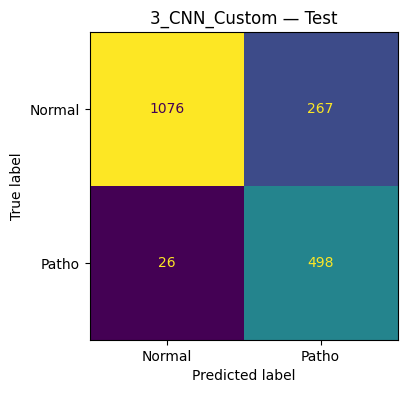

✅ [3_CNN_Custom] TEST → recall_patho=0.950 | spécificité=0.801 | F1=0.773 | AUC=0.955


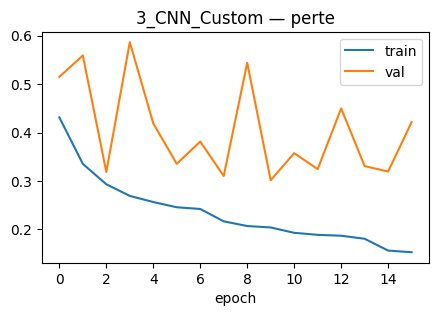

In [14]:
class CardioCNN(nn.Module):
    def __init__(self):
        super().__init__()
        def block(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(1, 16), block(16, 32), block(32, 64), block(64, 128))
        self.pool = nn.AdaptiveAvgPool2d(1)        # moyenne globale -> indépendant de la durée exacte
        self.head = nn.Sequential(nn.Dropout(0.4), nn.Linear(128, 2))
    def forward(self, x):
        return self.head(self.pool(self.features(x)).flatten(1))

model, hist, secs = train_torch(CardioCNN(), "CNN", epochs=25, lr=1e-3)
finish_torch(model, hist, secs, "3_CNN_Custom", "cnn_custom", {"epochs_max": 25, "lr": 1e-3, "batch": BATCH, "arch": "4 conv blocks"})

## 6.5 — Algorithme 4 : CNN pré-entraîné (Transfer Learning) — ResNet18
**Transfer learning** : on réutilise un ResNet18 entraîné sur ImageNet (millions d'images) qui sait déjà détecter bords/textures, puis on l'adapte à nos spectrogrammes :
- la 1ʳᵉ couche accepte **1 canal** (on additionne les poids RGB d'origine),
- la dernière couche est remplacée par 2 sorties (normal / patho),
- on ré-entraîne tout avec un **petit learning rate** (fine-tuning).

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 164MB/s]


  ep 01/20 | train_loss=0.3308 val_loss=0.3108 | val recall=0.929 spec=0.807
  ep 04/20 | train_loss=0.1663 val_loss=0.3740 | val recall=0.807 spec=0.885
  ep 07/20 | train_loss=0.0523 val_loss=0.4256 | val recall=0.888 spec=0.866
  ep 10/20 | train_loss=0.0182 val_loss=0.6778 | val recall=0.785 spec=0.915
  ep 13/20 | train_loss=0.0042 val_loss=0.7682 | val recall=0.777 spec=0.922
  ep 16/20 | train_loss=0.0013 val_loss=0.8912 | val recall=0.773 spec=0.926
  ⏹ early stopping


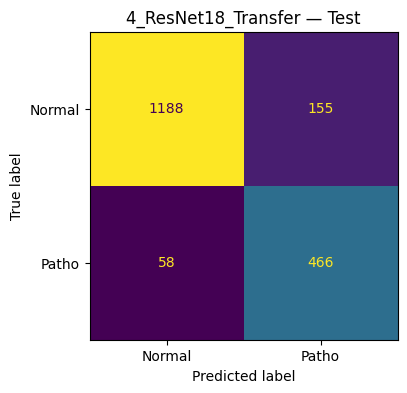

✅ [4_ResNet18_Transfer] TEST → recall_patho=0.889 | spécificité=0.885 | F1=0.814 | AUC=0.954


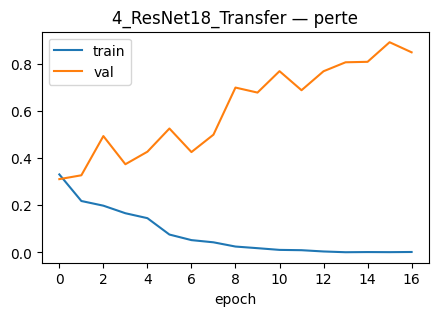

In [15]:
import torchvision
def make_resnet18():
    try:
        m = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.DEFAULT)
        pretrained = True
    except Exception as e:
        print("⚠️ Poids ImageNet indisponibles, ResNet18 initialisé au hasard :", e)
        m, pretrained = torchvision.models.resnet18(weights=None), False
    w = m.conv1.weight.data.sum(dim=1, keepdim=True)          # RGB -> 1 canal
    m.conv1 = nn.Conv2d(1, 64, 7, 2, 3, bias=False); m.conv1.weight.data = w
    m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, 2))
    return m, pretrained

m, pretrained = make_resnet18()
model, hist, secs = train_torch(m, "ResNet18", epochs=20, lr=3e-4)
finish_torch(model, hist, secs, "4_ResNet18_Transfer", "resnet18", {"epochs_max": 20, "lr": 3e-4, "pretrained_imagenet": pretrained, "backbone": "resnet18"})

## 6.6 — Algorithme 5 : Transformer-CNN hybride
- Le **CNN** extrait des motifs locaux dans le spectrogramme.
- Le **Transformer** (mécanisme d'*attention*) relie ensuite les **instants entre eux** : il capte la structure temporelle des bruits **B1 (« lub »)** et **B2 (« dub »)** et de leur espacement (cycle cardiaque).
(Version légère entraînable depuis zéro ; l'AST/Conformer pré-entraîné serait trop lourd pour Colab.)

  ep 01/25 | train_loss=0.5092 val_loss=0.3842 | val recall=0.911 spec=0.746
  ep 04/25 | train_loss=0.3037 val_loss=0.3298 | val recall=0.972 spec=0.734
  ep 07/25 | train_loss=0.2667 val_loss=0.3312 | val recall=0.872 spec=0.844
  ep 10/25 | train_loss=0.2376 val_loss=0.3369 | val recall=0.868 spec=0.843
  ep 13/25 | train_loss=0.1968 val_loss=0.3485 | val recall=0.830 spec=0.871
  ep 16/25 | train_loss=0.1829 val_loss=0.3823 | val recall=0.793 spec=0.898
  ep 19/25 | train_loss=0.1403 val_loss=0.4076 | val recall=0.828 spec=0.888
  ep 22/25 | train_loss=0.1169 val_loss=0.5098 | val recall=0.759 spec=0.910
  ep 25/25 | train_loss=0.0997 val_loss=0.4782 | val recall=0.809 spec=0.895


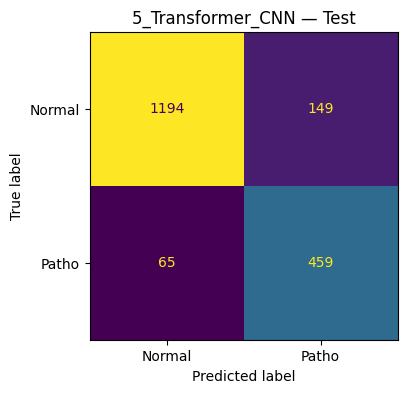

✅ [5_Transformer_CNN] TEST → recall_patho=0.876 | spécificité=0.889 | F1=0.811 | AUC=0.953


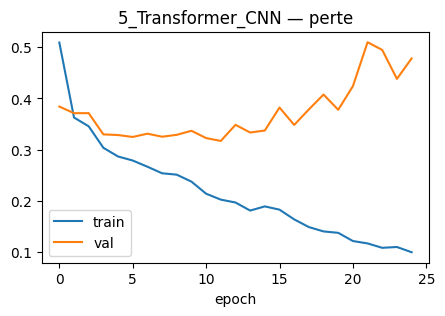

In [16]:
class CNNTransformer(nn.Module):
    def __init__(self, n_mels=N_MELS, d_model=96, nhead=4, layers=2, max_t=512):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d((2, 1)),   # réduit la fréquence seulement
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d((2, 2)),  # réduit fréquence ET temps
        )
        self.proj = nn.Linear(64 * (n_mels // 4), d_model)           # chaque instant -> vecteur de taille d_model
        self.pos = nn.Parameter(torch.zeros(1, max_t, d_model))      # encodage de position (appris)
        enc = nn.TransformerEncoderLayer(d_model, nhead, dim_feedforward=2 * d_model, dropout=0.2, batch_first=True)
        self.transformer = nn.TransformerEncoder(enc, layers, enable_nested_tensor=False)
        self.head = nn.Sequential(nn.LayerNorm(d_model), nn.Dropout(0.3), nn.Linear(d_model, 2))
    def forward(self, x):
        z = self.cnn(x)                                  # (B, 64, F/4, T/2)
        B, C, Fq, T = z.shape
        z = z.permute(0, 3, 1, 2).reshape(B, T, C * Fq)  # (B, T, 64*F/4) : séquence temporelle
        z = self.proj(z) + self.pos[:, :T]
        z = self.transformer(z)                          # attention entre tous les instants
        return self.head(z.mean(dim=1))

model, hist, secs = train_torch(CNNTransformer(), "CNN-Transformer", epochs=25, lr=5e-4)
finish_torch(model, hist, secs, "5_Transformer_CNN", "cnn_transformer", {"epochs_max": 25, "lr": 5e-4, "d_model": 96, "heads": 4, "layers": 2})

## 7️⃣ Comparaison des 5 algorithmes
Tableau récapitulatif (métriques sur le **jeu de test**, jamais vu pendant l'entraînement).

,accuracy,recall_patho,specificity,precision,f1,auc
Modèle,,,,,,
1. Decision Tree,0.781000,0.945000,0.717000,0.566000,0.708000,0.875000
2. SVM (RBF),0.860000,0.941000,0.828000,0.681000,0.790000,0.948000
3. CNN Custom,0.843000,0.950000,0.801000,0.651000,0.773000,0.955000
4. ResNet18 (TL),0.886000,0.889000,0.885000,0.750000,0.814000,0.954000
5. Transformer-CNN,0.885000,0.876000,0.889000,0.755000,0.811000,0.953000


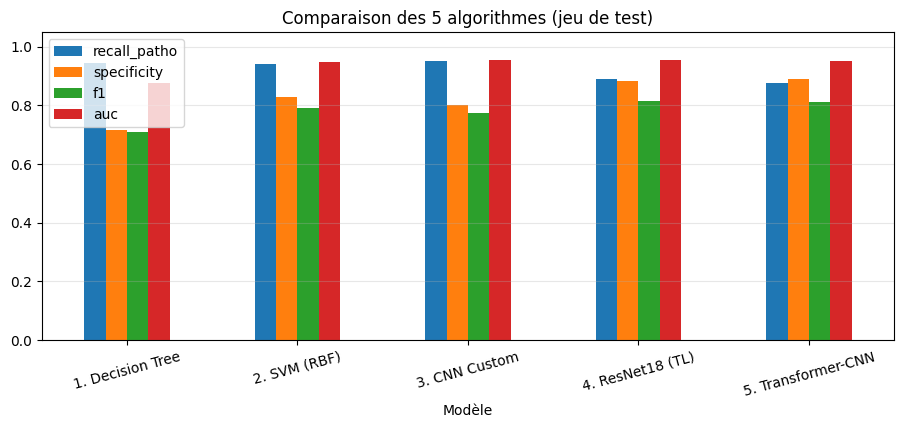

In [17]:
names = {"DecisionTree": "1. Decision Tree", "SVM_RBF": "2. SVM (RBF)", "cnn_custom": "3. CNN Custom",
         "resnet18": "4. ResNet18 (TL)", "cnn_transformer": "5. Transformer-CNN"}
rows = []
for k, r in RESULTS.items():
    rows.append({"Modèle": names.get(k, k), **{f"{mk}": round(mv, 3) for mk, mv in r["test"].items()}})
df_res = pd.DataFrame(rows).set_index("Modèle")
display(df_res.style.highlight_max(axis=0, color="#c8f7c5"))

df_res[["recall_patho", "specificity", "f1", "auc"]].plot(kind="bar", figsize=(11, 4), rot=15)
plt.title("Comparaison des 5 algorithmes (jeu de test)"); plt.ylim(0, 1.05); plt.grid(axis="y", alpha=.3); plt.show()

## 8️⃣ Sélection du meilleur modèle (critère : Recall pathologique)
Règle du PDF : maximiser le **Recall** sur la classe pathologique.
Garde-fou : on exige une **spécificité ≥ 0.5**, sinon un modèle qui déclare tout le monde malade gagnerait.
Les égalités sont départagées par le F1.

In [18]:
MIN_SPEC = 0.5
eligible = {k: r for k, r in RESULTS.items() if r["test"]["specificity"] >= MIN_SPEC} or RESULTS
ranking = sorted(eligible.items(), key=lambda kv: (kv[1]["test"]["recall_patho"], kv[1]["test"]["f1"]), reverse=True)
print("Classement :")
for i, (k, r) in enumerate(ranking, 1):
    print(f"  {i}. {names.get(k,k):22s} recall={r['test']['recall_patho']:.3f}  spec={r['test']['specificity']:.3f}  f1={r['test']['f1']:.3f}")
best_key = ranking[0][0]
print(f"\n🏆 Meilleur modèle : {names.get(best_key, best_key)}")

# Trace le choix dans MLflow
with mlflow.start_run(run_name="0_MODEL_SELECTION"):
    mlflow.log_param("best_model", names.get(best_key, best_key))
    mlflow.log_param("selection_rule", f"max recall_patho with specificity >= {MIN_SPEC}")
    mlflow.log_metrics({f"best_{k}": v for k, v in RESULTS[best_key]["test"].items()})

Classement :
  1. 3. CNN Custom          recall=0.950  spec=0.801  f1=0.773
  2. 1. Decision Tree       recall=0.945  spec=0.717  f1=0.708
  3. 2. SVM (RBF)           recall=0.941  spec=0.828  f1=0.790
  4. 4. ResNet18 (TL)       recall=0.889  spec=0.885  f1=0.814
  5. 5. Transformer-CNN     recall=0.876  spec=0.889  f1=0.811

🏆 Meilleur modèle : 3. CNN Custom


## 9️⃣ Export ONNX (`cardio_model.onnx`) + vérification
**ONNX** = format standard et portable : le service `audio-engine` (Docker, ONNX Runtime) pourra l'utiliser **sans PyTorch ni scikit-learn**.
- Modèle sklearn (SVM/Arbre) → `skl2onnx` (le `StandardScaler` est inclus dans le graphe).
- Modèle PyTorch → `torch.onnx.export` (avec la normalisation + softmax intégrés, batch dynamique).
Puis on **vérifie** avec ONNX Runtime que les prédictions sont identiques à celles du modèle d'origine.
Si l'export du meilleur échoue, on passe automatiquement au suivant du classement.

In [19]:
import onnx, onnxruntime as ort
from skl2onnx import convert_sklearn
from skl2onnx.common.data_types import FloatTensorType

ONNX_PATH = os.path.join(OUTPUT_DIR, "cardio_model.onnx")

class TorchWrapped(nn.Module):
    # Ajoute normalisation + softmax DANS le graphe ONNX -> l'entrée est directement le log-mel brut.
    def __init__(self, m, mean, std):
        super().__init__(); self.m = m.eval(); self.register_buffer("mean", torch.tensor(mean)); self.register_buffer("std", torch.tensor(std))
    def forward(self, x):
        return F.softmax(self.m((x - self.mean) / self.std), dim=1)

def export_and_verify(key):
    r = RESULTS[key]
    if r["kind"] == "sklearn":
        clf = r["model"].steps[-1][1]
        onx = convert_sklearn(r["model"], initial_types=[("features", FloatTensorType([None, r["n_features"]]))],
                              options={id(clf): {"zipmap": False}})
        with open(ONNX_PATH, "wb") as f: f.write(onx.SerializeToString())
        sess = ort.InferenceSession(ONNX_PATH, providers=["CPUExecutionProvider"])
        out = sess.run(None, {"features": X1_te[:200].astype(np.float32)})
        onnx_pred = out[0].astype(int).ravel(); sk_pred = r["model"].predict(X1_te[:200])
        agree = float(np.mean(onnx_pred == sk_pred))
        meta = dict(model=names.get(key, key), input_type="mfcc_features", input_name="features", n_features=int(r["n_features"]))
    else:
        w = TorchWrapped(r["model"].cpu(), MEL_MEAN, MEL_STD).eval()
        dummy = torch.randn(1, *INPUT_SHAPE)
        torch.onnx.export(w, dummy, ONNX_PATH, input_names=["log_mel"], output_names=["probabilities"],
                          dynamic_axes={"log_mel": {0: "batch"}, "probabilities": {0: "batch"}}, opset_version=17, dynamo=False)
        sess = ort.InferenceSession(ONNX_PATH, providers=["CPUExecutionProvider"])
        xb = to_tensor(X2_te[:100])
        onnx_p = sess.run(None, {"log_mel": xb.numpy()})[0]
        with torch.no_grad(): torch_p = w(xb).numpy()
        agree = float(np.mean(onnx_p.argmax(1) == torch_p.argmax(1)))
        print("   écart max des probabilités PyTorch vs ONNX :", float(np.abs(onnx_p - torch_p).max()))
        meta = dict(model=names.get(key, key), input_type="log_mel", input_name="log_mel", input_shape=[1, *INPUT_SHAPE])
    onnx.checker.check_model(onnx.load(ONNX_PATH))
    print(f"   ✔ accord ONNX vs modèle d'origine : {agree*100:.1f} %")
    assert agree > 0.95, "Accord insuffisant"
    meta.update(sample_rate=SR, duration_s=DURATION, n_mels=N_MELS, n_fft=N_FFT, hop_length=HOP, n_mfcc=N_MFCC,
                bandpass_hz=[25, 400], classes=["normal", "pathologique"],
                mel_mean=MEL_MEAN, mel_std=MEL_STD, test_metrics={k: float(v) for k, v in r["test"].items()})
    with open(os.path.join(OUTPUT_DIR, "cardio_model_meta.json"), "w") as f: json.dump(meta, f, indent=2)
    return meta

exported = None
for k, _ in ranking:
    print(f"Tentative d'export : {names.get(k, k)}")
    try:
        exported = export_and_verify(k); exported["key"] = k; break
    except Exception as e:
        print("   ✖ échec :", repr(e)[:300])
assert exported, "Aucun export ONNX n'a réussi"

with mlflow.start_run(run_name="9_ONNX_EXPORT"):
    mlflow.log_param("exported_model", exported["model"])
    mlflow.log_artifact(ONNX_PATH); mlflow.log_artifact(os.path.join(OUTPUT_DIR, "cardio_model_meta.json"))
print("\n✅ Fichier exporté :", ONNX_PATH, f"({os.path.getsize(ONNX_PATH)/1e6:.2f} Mo)")

Tentative d'export : 3. CNN Custom
   écart max des probabilités PyTorch vs ONNX : 2.682209014892578e-07
   ✔ accord ONNX vs modèle d'origine : 100.0 %

✅ Fichier exporté : /content/drive/MyDrive/CardioAgentOps_outputs/cardio_model.onnx (0.39 Mo)


## 🔟 Test d'inférence ONNX de bout en bout (comme dans `audio-engine`)
On prend un vrai `.wav`, on applique **le même prétraitement**, puis on prédit avec **ONNX Runtime uniquement**. La probabilité finale = moyenne sur les fenêtres de 5 s.

In [20]:
sess = ort.InferenceSession(ONNX_PATH, providers=["CPUExecutionProvider"])
meta = json.load(open(os.path.join(OUTPUT_DIR, "cardio_model_meta.json")))

def predict_wav(path):
    segs = preprocess_file(path)
    if not segs: return {"error": "audio trop court"}
    S = [mel_spectrogram_db(s) for s in segs]
    if meta["input_type"] == "mfcc_features":
        X = np.stack([feature_vector(s, sd) for s, sd in zip(segs, S)]).astype(np.float32)
        probs = sess.run(None, {"features": X})[1]
    else:
        X = np.stack(S)[:, None].astype(np.float32)
        probs = sess.run(None, {"log_mel": X})[0]
    p = float(np.mean(probs[:, 1]))
    return {"fichier": os.path.basename(path), "prob_pathologique": round(p, 3),
            "prediction": "pathologique" if p >= 0.5 else "normal", "nb_fenetres": len(segs)}

for lab in [0, 1]:
    sample = df_te[df_te.label == lab].path.iloc[0] if (df_te.label == lab).any() else df_rec[df_rec.label == lab].path.iloc[0]
    print("Vrai label =", "pathologique" if lab else "normal", "→", predict_wav(sample))

Vrai label = normal → {'fichier': 'f0015.wav', 'prob_pathologique': 0.254, 'prediction': 'normal', 'nb_fenetres': 6}
Vrai label = pathologique → {'fichier': '198_1308141739338_B.wav', 'prob_pathologique': 0.88, 'prediction': 'pathologique', 'nb_fenetres': 1}


## 💾 Sauvegarde de MLflow dans Drive + visualiser les runs

In [21]:
import shutil
runs = mlflow.search_runs(experiment_names=[EXP_NAME])
cols = [c for c in runs.columns if c.startswith("tags.mlflow.runName") or c.startswith("metrics.test_")]
display(runs[cols].sort_values("metrics.test_recall_patho", ascending=False))

# Copie de la base MLflow + artefacts dans Drive (pour les retrouver / montrer au prof)
shutil.copy("/content/mlflow.db", os.path.join(OUTPUT_DIR, "mlflow.db"))
shutil.copytree("/content/mlartifacts", os.path.join(OUTPUT_DIR, "mlartifacts"), dirs_exist_ok=True)
runs.to_csv(os.path.join(OUTPUT_DIR, "mlflow_runs_summary.csv"), index=False)
print("Sauvegardé dans :", OUTPUT_DIR)

,metrics.test_recall_patho,metrics.test_f1,metrics.test_specificity,metrics.test_accuracy,metrics.test_auc,metrics.test_precision,tags.mlflow.runName
4,0.950382,0.772692,0.801191,0.843064,0.955433,0.650980,3_CNN_Custom
6,0.944656,0.707648,0.717051,0.780932,0.874609,0.565714,1_DecisionTree
5,0.940840,0.790064,0.827997,0.859668,0.948102,0.680939,2_SVM_RBF
3,0.889313,0.813974,0.884587,0.885913,0.954451,0.750403,4_ResNet18_Transfer
2,0.875954,0.810954,0.889054,0.885378,0.952850,0.754934,5_Transformer_CNN
0,NaN,NaN,NaN,NaN,NaN,NaN,9_ONNX_EXPORT
1,NaN,NaN,NaN,NaN,NaN,NaN,0_MODEL_SELECTION


Sauvegardé dans : /content/drive/MyDrive/CardioAgentOps_outputs


### (Optionnel) Ouvrir l'interface web MLflow dans Colab
```python
!pip install -q pyngrok
from pyngrok import ngrok
ngrok.set_auth_token("TON_TOKEN_NGROK")   # compte gratuit sur ngrok.com
get_ipython().system_raw("mlflow ui --backend-store-uri sqlite:////content/mlflow.db --port 5000 &")
print(ngrok.connect(5000))
```
En local (après avoir téléchargé `mlflow.db` et `mlartifacts/`) : `mlflow ui --backend-store-uri sqlite:///mlflow.db`.

---
### ✅ Récapitulatif par rapport au PDF
- [x] Rééchantillonnage 2000 Hz, normalisation 5 s, MFCC / ZCR / Spectrogrammes Mel
- [x] Benchmark des 5 algorithmes : Decision Tree, SVM RBF, CNN Custom, ResNet18 TL, Transformer-CNN
- [x] Runs MLflow systématiques (paramètres, métriques, matrices de confusion, courbes de perte)
- [x] Sélection par Recall de la classe pathologique
- [x] Export `cardio_model.onnx` vérifié avec ONNX Runtime
- [ ] Prochaine étape (jalon suivant) : brancher `cardio_model.onnx` + `cardio_model_meta.json` dans le service **audio-engine** (Docker) et le tester dans `test_audio.py`.